In [59]:
import numpy as np
import pandas as pd

df = pd.read_csv("data/case1/train1.csv")
df["kilo_rpm"] = df["speed_rpm"] / 1000

test_df = pd.read_csv("data/case1/test1.csv")
test_df["kilo_rpm"] = test_df["speed_rpm"] / 1000

y_train = df["power_w"]
y_test = test_df["power_w"]

from sklearn.preprocessing import PolynomialFeatures
poly = PolynomialFeatures(degree=3, include_bias=False)

X_train = poly.fit_transform(df[["kilo_rpm", "flow_m3_h"]])
X_test = poly.transform(test_df[["kilo_rpm", "flow_m3_h"]])


from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X_train, y_train)

predictions = model.predict(X_test)

from sklearn.metrics import mean_squared_error, r2_score
print(r2_score(y_test, predictions))

0.9996310409011722


In [81]:

import numpy as np
import pandas as pd

df = pd.read_csv("data/case1/train1.csv")
df["kilo_rpm"] = df["speed_rpm"] / 1000
dataset = df[["power_w"]].copy()

dataset['kilo_rpm'] = df["kilo_rpm"]
dataset['kilo_rpm * flow_m3_h'] = df["kilo_rpm"] * df["flow_m3_h"]
dataset['kilo_rpm * flow_m3_h**2'] = df["kilo_rpm"] * df["flow_m3_h"]**2
dataset['kilo_rpm * flow_m3_h**3'] = df["kilo_rpm"] * df["flow_m3_h"]**3

dataset['kilo_rpm**2'] = df["kilo_rpm"]**2
dataset['kilo_rpm**2 * flow_m3_h'] = df["kilo_rpm"]**2 * df["flow_m3_h"]
dataset['kilo_rpm**2 * flow_m3_h**2'] = df["kilo_rpm"]**2 * df["flow_m3_h"]**2
dataset['kilo_rpm**2 * flow_m3_h**3'] = df["kilo_rpm"]**2 * df["flow_m3_h"]**3

dataset['kilo_rpm**3'] = df["kilo_rpm"]**3
dataset['kilo_rpm**3 * flow_m3_h'] = df["kilo_rpm"]**3 * df["flow_m3_h"]
dataset['kilo_rpm**3 * flow_m3_h**2'] = df["kilo_rpm"]**3 * df["flow_m3_h"]**2
dataset['kilo_rpm**3 * flow_m3_h**3'] = df["kilo_rpm"]**3 * df["flow_m3_h"]**3

dataset["flow_m3_h"] = df["flow_m3_h"]
dataset["flow_m3_h**2"] = df["flow_m3_h"]**2
dataset["flow_m3_h**3"] = df["flow_m3_h"]**3

dataset["constant"] = 1

In [82]:
test_df = pd.read_csv("data/case1/test1.csv")
test_df["kilo_rpm"] = test_df["speed_rpm"] / 1000

test_dataset = test_df[["power_w"]].copy()

test_dataset['kilo_rpm'] = test_df["kilo_rpm"]
test_dataset['kilo_rpm * flow_m3_h'] = test_df["kilo_rpm"] * test_df["flow_m3_h"]
test_dataset['kilo_rpm * flow_m3_h**2'] = test_df["kilo_rpm"] * test_df["flow_m3_h"]**2
test_dataset['kilo_rpm * flow_m3_h**3'] = test_df["kilo_rpm"] * test_df["flow_m3_h"]**3

test_dataset['kilo_rpm**2'] = test_df["kilo_rpm"]**2
test_dataset['kilo_rpm**2 * flow_m3_h'] = test_df["kilo_rpm"]**2 * test_df["flow_m3_h"]
test_dataset['kilo_rpm**2 * flow_m3_h**2'] = test_df["kilo_rpm"]**2 * test_df["flow_m3_h"]**2
test_dataset['kilo_rpm**2 * flow_m3_h**3'] = test_df["kilo_rpm"]**2 * test_df["flow_m3_h"]**3

test_dataset['kilo_rpm**3'] = test_df["kilo_rpm"]**3
test_dataset['kilo_rpm**3 * flow_m3_h'] = test_df["kilo_rpm"]**3 * test_df["flow_m3_h"]
test_dataset['kilo_rpm**3 * flow_m3_h**2'] = test_df["kilo_rpm"]**3 * test_df["flow_m3_h"]**2
test_dataset['kilo_rpm**3 * flow_m3_h**3'] = test_df["kilo_rpm"]**3 * test_df["flow_m3_h"]**3

test_dataset["flow_m3_h"] = test_df["flow_m3_h"]
test_dataset["flow_m3_h**2"] = test_df["flow_m3_h"]**2
test_dataset["flow_m3_h**3"] = test_df["flow_m3_h"]**3

test_dataset["constant"] = 1

In [74]:
target = "power_w"
feature_names = [column for column in dataset.columns if column != target]

In [66]:
target = "power_w"
feature_names = ["kilo_rpm", "flow_m3_h", "kilo_rpm * flow_m3_h", "kilo_rpm**3", "kilo_rpm**2"]

In [75]:
from sklearn.linear_model import LinearRegression
X = dataset[feature_names].to_numpy(dtype=float)
y = dataset[target].to_numpy(dtype=float)

model = LinearRegression()
model.fit(X, y)

print([float(coef) for coef in model.coef_])
print(model.intercept_) 

[19.157724835285464, 8.78114163318766, -0.9305218681158514, 0.022148089198067843, -6.224519594003488, -0.20360933692196512, 0.2536972918629747, -0.006255158149312499, 8.281944447145099, 0.24941232552910114, -0.023432612981385232, 0.0005675968875949815, -9.418275197459439, 0.9693816119983449, -0.033268553774313106, 0.0]
23.444468629039534


In [76]:
terms = list(zip(feature_names, model.coef_))

terms.sort(key=lambda x: abs(x[1]))

for name, coef in terms:
    print(f"{name:35}{coef:.6f}")

constant                           0.000000
kilo_rpm**3 * flow_m3_h**3         0.000568
kilo_rpm**2 * flow_m3_h**3         -0.006255
kilo_rpm * flow_m3_h**3            0.022148
kilo_rpm**3 * flow_m3_h**2         -0.023433
flow_m3_h**3                       -0.033269
kilo_rpm**2 * flow_m3_h            -0.203609
kilo_rpm**3 * flow_m3_h            0.249412
kilo_rpm**2 * flow_m3_h**2         0.253697
kilo_rpm * flow_m3_h**2            -0.930522
flow_m3_h**2                       0.969382
kilo_rpm**2                        -6.224520
kilo_rpm**3                        8.281944
kilo_rpm * flow_m3_h               8.781142
flow_m3_h                          -9.418275
kilo_rpm                           19.157725


In [77]:
from sklearn.metrics import mean_squared_error, r2_score

X_test = test_dataset[feature_names].to_numpy(dtype=float)
y_test = test_dataset[target].to_numpy(dtype=float)

predictions = model.predict(X_test)

mse = mean_squared_error(y_test, predictions)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, predictions)

print(f"Test MSE:  {mse:.3f}")
print(f"Test RMSE: {rmse:.3f} w")
print(f"Test R²:   {r2:.10f}")

Test MSE:  108.032
Test RMSE: 10.394 w
Test R²:   0.9996267676


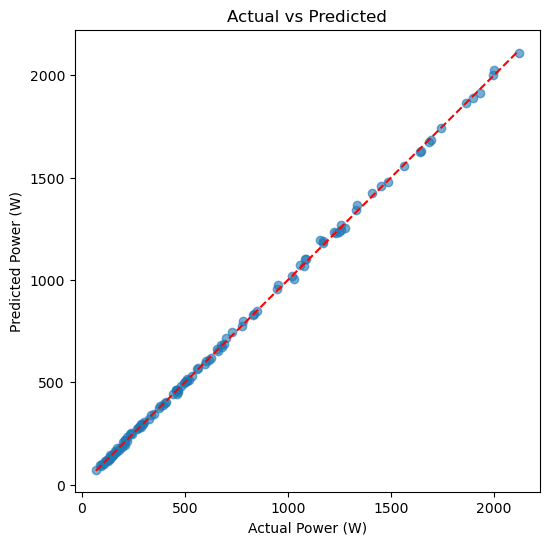

In [78]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,6))
plt.scatter(y_test, predictions, alpha=0.6)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.xlabel("Actual Power (W)")
plt.ylabel("Predicted Power (W)")
plt.title("Actual vs Predicted")
plt.show()

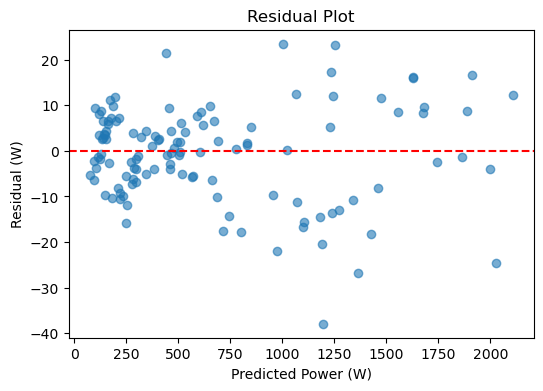

In [79]:
residuals = y_test - predictions

plt.figure(figsize=(6,4))
plt.scatter(predictions, residuals, alpha=0.6)

plt.axhline(0, color='red', linestyle='--')

plt.xlabel("Predicted Power (W)")
plt.ylabel("Residual (W)")
plt.title("Residual Plot")
plt.show()

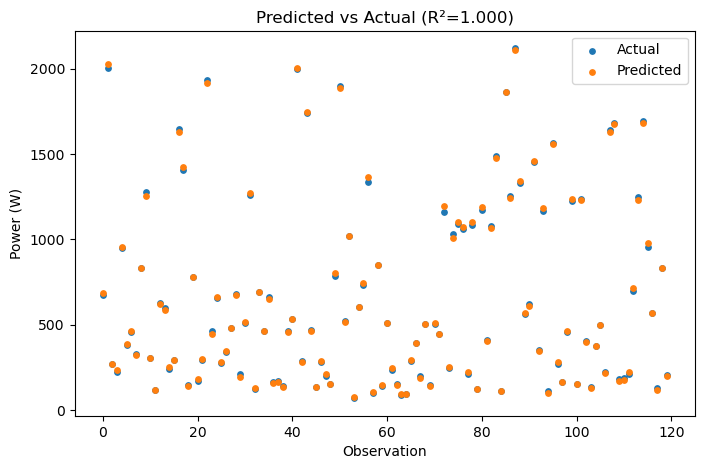

In [80]:
plt.figure(figsize=(8,5))

plt.scatter(range(len(y_test)), y_test,
            label="Actual", s=15)

plt.scatter(range(len(predictions)), predictions,
            label="Predicted", s=15)

plt.xlabel("Observation")
plt.ylabel("Power (W)")
plt.title(f"Predicted vs Actual (R²={r2:.3f})")
plt.legend()

plt.show()